In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split # model selection
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# 1. Load data
df = pd.read_csv('homeprices.csv')
print(df.shape)
print(df.isnull().sum())      # check for missing values
df = df.dropna()              # safety: drop any null rows

(50000, 4)
area        0
bedrooms    0
age         0
price       0
dtype: int64


In [3]:
# 2. Features and target
X = df[['area', 'bedrooms', 'age']]
y = df['price']

# 3. Hold-out split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 )
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

Train size: 40000 | Test size: 10000


In [4]:
# 4. Train
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [5]:
# 5. Predict
y_test_pred = model.predict(X_test)

In [6]:
# 6. Evaluate
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"\n{name}")
    print(f"  MAE  : {mae:,.2f}")
    print(f"  MSE  : {mse:,.2f}")
    print(f"  RMSE : {rmse:,.2f}")
    print(f"  R2   : {r2:.4f}")

evaluate("Test set", y_test, y_test_pred)




Test set
  MAE  : 20,074.53
  MSE  : 633,903,560.84
  RMSE : 25,177.44
  R2   : 0.9750


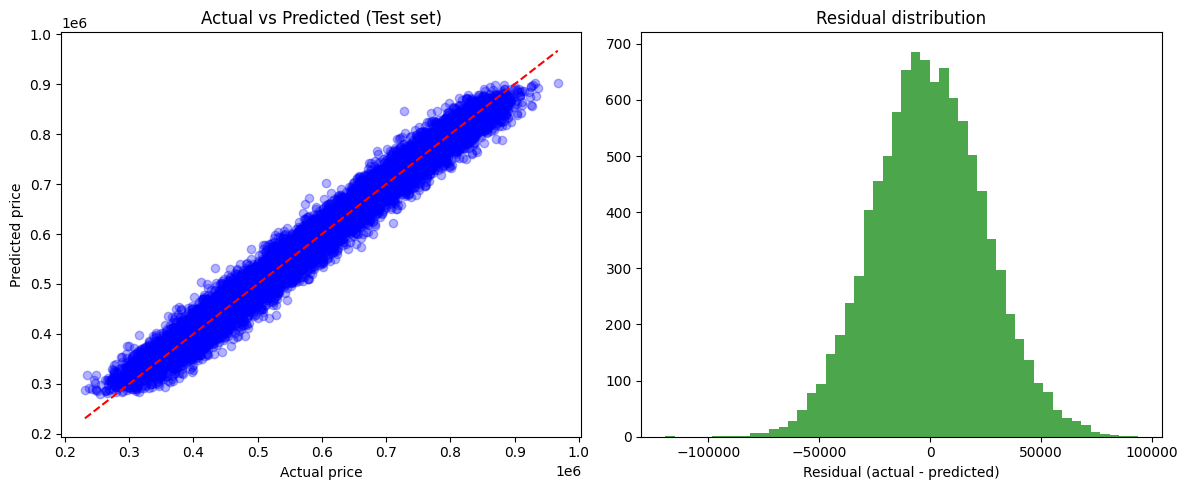

In [7]:
# 7. Plots
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Actual vs predicted
ax[0].scatter(y_test, y_test_pred, alpha=0.3, color='blue')
ax[0].plot([y_test.min(), y_test.max()],
           [y_test.min(), y_test.max()], 'r--')
ax[0].set_xlabel('Actual price')
ax[0].set_ylabel('Predicted price')
ax[0].set_title('Actual vs Predicted (Test set)')

# Residuals
residuals = y_test - y_test_pred
ax[1].hist(residuals, bins=50, color='green', alpha=0.7)
ax[1].set_xlabel('Residual (actual - predicted)')
ax[1].set_title('Residual distribution')

plt.tight_layout()
plt.show()



In [10]:
# 8. Predict a new house
new_house = pd.DataFrame({'area': [3000], 'bedrooms': [2], 'age': [40]})
print("\nPredicted price:", round(model.predict(new_house)[0], 2))


Predicted price: 550059.8
